# Phase 2 -- real oil-slick data, end-to-end pipeline

**Scope.** This is an orchestration + visualization notebook only. Every
scientific computation is delegated to the existing, unmodified `iste/` modules
(T07 upstream adapter, Stage III backward transport, T14-T25 Phase 2 machinery,
including `iste.phase2_pipeline.run_phase2_pipeline`, T26's own integration). No
backward SDE, KD-tree, KDE/support, candidate detection, weighted sampling,
forward propagation, accuracy metric, or ranking algorithm is reimplemented here.

**Real-data labeling (read this first).**

- The **actual satellite observation** used is `ow-0008.jpg` (548 real detected oil
  parcels, true timestamp `2019-06-14T20:35:58`) from `data/database_payload.json`.
- The only real ocean-current data available in this repository
  (`data/ocean.nc`/`data/wind.nc`) covers `2019-10-01` .. `2019-10-14` -- a
  **different date than the true observation**. Per explicit instruction, this
  notebook proceeds anyway, using the real 548 parcels together with the only real
  ocean-current data available, so the Phase 2 pipeline MECHANICS can be validated
  end-to-end on genuine data. **Every section below is labeled to make this mismatch
  impossible to miss** -- this run demonstrates that the pipeline works correctly on
  real inputs, not that the reconstructed source is physically accurate for the true
  June 2019 event.
- **Backward window scoping (explicit user decision):** the real ocean.nc dataset
  spans the full 14 days available, but running the complete 672-step/30-min
  backward window was estimated at ~75-90 minutes. The user explicitly chose to
  scope this run to **3 days at 1-hour steps (72 backward steps)** instead --
  recorded here for auditability, not a silent reduction.
- Backward-tracked particle positions are **historical transport STATES**, never
  described as observations.
- Support/hotspot scores are a **candidate-discovery screening signal**, never a
  posterior probability, and a hotspot is never called a confirmed source.
- Forward accuracy is a **physical-consistency screening quantity**, never a formal
  likelihood.
- The forcing ensemble actually used is stated explicitly in Section 2 below.

In [1]:
import os, sys, json, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap
import numpy as np

from iste.observation import adapt_upstream_particles
from iste.environment import load_field_dataset
from iste.forcing_ensemble import ForcingEnsemble, ForcingEnsembleConfig
from iste.ensemble_run import EnsembleRunRecords, run_ensemble
from iste.lookup_storage import ParticleRecordStore
from iste.particle_query import query_particle_slice
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.forward_budget import ForwardBudgetConfig
from iste.forward_accuracy import ComparisonConfig
from iste.candidate_screening import ScreeningConfig
from iste.phase2_pipeline import Phase2RunConfig, run_phase2_pipeline, save_phase2_artifact

RESULTS_DIR = os.path.join(REPO_ROOT, "results", "actual_data")
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"outputs will be saved under {RESULTS_DIR}")

outputs will be saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data


### I/O robustness note

This project directory is inside a OneDrive-synced folder. OneDrive's background
sync can transiently lock a just-written file for a moment, causing a spurious
`OSError` on the very next write to that same file -- pure infrastructure noise,
unrelated to any scientific computation. `save_with_retry` below retries a save a
few times before giving up; it wraps every file write in this notebook. This is
the only non-scientific helper in the notebook (plain I/O robustness).

In [2]:
def save_with_retry(save_callable, label="", retries=8, delay=2.0):
    last_err = None
    for attempt in range(retries):
        try:
            save_callable()
            return
        except OSError as e:
            last_err = e
            print(f"  [retry {attempt + 1}/{retries}] transient save error for {label}: {e}")
            time.sleep(delay)
    raise last_err

def save_animation_with_retry(anim, mp4_path, gif_path, fps, retries=8, delay=2.0):
    last_err = None
    for attempt in range(retries):
        try:
            anim.save(mp4_path, writer="ffmpeg", fps=fps, dpi=100)
            print(f"saved animation (MP4) to {mp4_path}")
            return
        except OSError as e:
            last_err = e
            print(f"  [retry {attempt + 1}/{retries}] transient save error for {mp4_path}: {e}")
            time.sleep(delay)
        except Exception as e:
            anim.save(gif_path, writer="pillow", fps=fps)
            print(f"ffmpeg unavailable ({e}); saved GIF to {gif_path}")
            return
    anim.save(gif_path, writer="pillow", fps=fps)
    print(f"MP4 save kept failing transiently ({last_err}); saved GIF to {gif_path} instead")

def write_json_with_retry(path, obj, label=""):
    def _do():
        with open(path, "w", encoding="utf-8") as f:
            json.dump(obj, f, indent=2)
    save_with_retry(_do, label=label or os.path.basename(path))

## 1. Actual input: the real detected oil slick (`ow-0008.jpg`)

Loaded from `data/database_payload.json` -- the real upstream detection record
with `image_filename`/`mask_filename`/`timestamp`/`area_pixels`/`bounding_box`/
`total_parcels`/`parcels[]` exactly as produced upstream. No synthetic particles
are generated anywhere in this notebook.

In [3]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
assert spill["total_parcels"] == 548 == len(spill["parcels"])

TRUE_OBS_TIMESTAMP = np.datetime64(spill["timestamp"], "ns")
print(f"image_filename : {spill['image_filename']}")
print(f"mask_filename  : {spill['mask_filename']}")
print(f"TRUE timestamp : {TRUE_OBS_TIMESTAMP}   <-- the actual detection time (real)")
print(f"area_pixels    : {spill['area_pixels']}")
print(f"bounding_box   : {spill['bounding_box']}")
print(f"total_parcels  : {spill['total_parcels']}")

write_json_with_retry(os.path.join(RESULTS_DIR, "observation_summary.json"), {
    "image_filename": spill["image_filename"], "mask_filename": spill["mask_filename"],
    "true_timestamp": spill["timestamp"], "area_pixels": spill["area_pixels"],
    "bounding_box": spill["bounding_box"], "total_parcels": spill["total_parcels"],
})
print("saved observation_summary.json")

image_filename : ow-0008.jpg
mask_filename  : mask_ow-0008.png
TRUE timestamp : 2019-06-14T20:35:58.000000000   <-- the actual detection time (real)
area_pixels    : 17712
bounding_box   : {'upper_left': {'lat': 34.007546490362, 'lon': 35.2080834959405}, 'bottom_right': {'lat': 34.1424457731161, 'lon': 35.3200266767827}}
total_parcels  : 548
saved observation_summary.json


### Observation visualization

The actual observed slick -- all 548 real parcels, colored by detection
confidence. **This is the observed slick at t_obs, labeled as such throughout.**

  [retry 1/8] transient save error for 01_observation.png: [Errno 22] Invalid argument: 'C:\\Users\\venka\\OneDrive\\Desktop\\SIH-2026\\project-v5\\results\\actual_data\\01_observation.png'


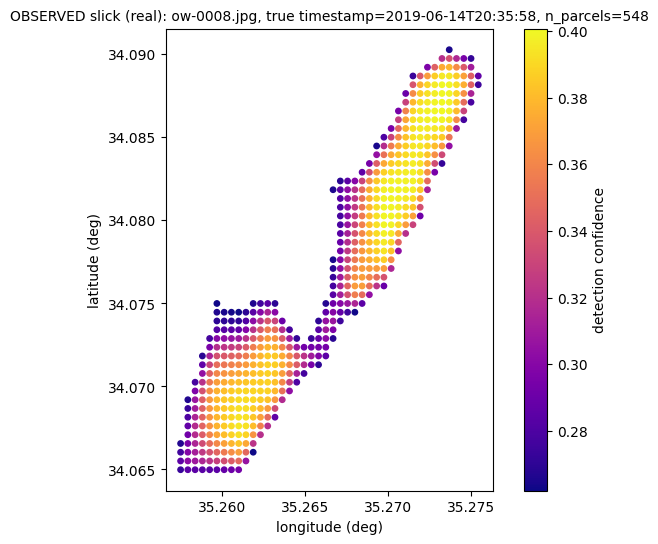

In [4]:
parcels = spill["parcels"]
obs_lat = np.array([p["lat"] for p in parcels])
obs_lon = np.array([p["lon"] for p in parcels])
obs_mass = np.array([p["mass_kg"] for p in parcels])
obs_conf = np.array([p["confidence"] for p in parcels])

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(obs_lon, obs_lat, c=obs_conf, s=15, cmap="plasma")
fig.colorbar(sc, ax=ax, label="detection confidence")
ax.set_title(f"OBSERVED slick (real): {spill['image_filename']}, true timestamp={spill['timestamp']}, n_parcels={spill['total_parcels']}", fontsize=10)
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)"); ax.set_aspect("equal")
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "01_observation.png"), dpi=110), label="01_observation.png")
plt.show()

## 2. KNOWN DATA MISMATCH -- environmental forcing data availability

**The only real ocean-current data in this repository (`data/ocean.nc`,
`data/wind.nc`) covers `2019-10-01` .. `2019-10-14`.** The true observation
(`ow-0008.jpg`) is from `2019-06-14`. None of the 5 real spill records in
`data/database_payload.json` (Jan/Apr/Jun/Sep/Dec 2019) fall inside that Oct 1-14
window either. Per explicit instruction, this run proceeds using the real 548
parcels together with the only real ocean data available, with `t_obs` set to the
LAST available ocean.nc checkpoint (`2019-10-14T23:00:00`) instead of the true
observation time -- **this validates pipeline mechanics on real data; it is NOT a
physically accurate reconstruction of the true June 2019 event.** This mismatch is
carried in every subsequent plot/table title as `RUN_T_OBS` (the run's own anchor
time) vs. the `TRUE_OBS_TIMESTAMP` printed above.

In [5]:
OCEAN_PATH = os.path.join(REPO_ROOT, "data", "ocean.nc")
ocean = load_field_dataset(OCEAN_PATH, ["uo", "vo"], time_dim="time", lat_dim="latitude", lon_dim="longitude")
print(f"ocean.nc: grid {ocean.lat.shape} x {ocean.lon.shape}, time {ocean.time[0]} .. {ocean.time[-1]} ({len(ocean.time)} hourly steps)")

RUN_T_OBS = ocean.time[-1]
print(f"RUN t_obs (only real ocean data available): {RUN_T_OBS}")
print(f"TRUE observation timestamp (not used for forcing): {TRUE_OBS_TIMESTAMP}")

# Forcing ensemble: README.md's own stated configured default is n_members=50.
# ACTUAL run uses an EXPLICIT, RECORDED development subset of 6 members (real-data
# scale: 548 particles x 50 members x many backward steps is not practical in this
# session -- README.md explicitly allows a recorded development subset; it must
# never be a SILENT substitution, so it is stated here and in every output).
FULL_ENSEMBLE_N_MEMBERS_CONFIGURED = 50
FORCING_MEMBER_IDS_USED = (0, 1, 2, 3, 4, 5)
print(f"Configured full ensemble: {FULL_ENSEMBLE_N_MEMBERS_CONFIGURED} members. "
      f"ACTUAL members used in this real run: {FORCING_MEMBER_IDS_USED} "
      f"({len(FORCING_MEMBER_IDS_USED)} of {FULL_ENSEMBLE_N_MEMBERS_CONFIGURED}, explicit recorded development subset)")

ensemble_config = ForcingEnsembleConfig(n_members=FULL_ENSEMBLE_N_MEMBERS_CONFIGURED, master_seed=7)
ensemble = ForcingEnsemble(ocean, ensemble_config)
K_DIFFUSIVITY = 3.0  # m^2/s, explicit PROTOTYPE constant -- no real K field exists (T01.5/T03)
K = np.full((len(ocean.lat), len(ocean.lon)), K_DIFFUSIVITY)

# Land/invalid-domain background for plots: reuses ocean.nc's OWN mask (a cell that is NaN
# at every single timestep) -- the exact same mask T04's boundary policy (apply_boundary_policy/
# netcdf_validity_check, unmodified) already checks against. Not a new land model, just a
# visualization of existing masked data.
land_mask_grid = np.all(np.isnan(ocean.data["uo"]), axis=0)
print(f"land/invalid-domain cells in ocean.nc grid: {int(land_mask_grid.sum())}/{land_mask_grid.size}")
LAND_CMAP = ListedColormap(["#c2b280"])

def add_land_background(ax):
    masked = np.ma.masked_where(~land_mask_grid, land_mask_grid.astype(float))
    ax.pcolormesh(ocean.lon, ocean.lat, masked, shading="auto", cmap=LAND_CMAP, zorder=0)

C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'ImportError'>
cannot import name '_quote_string_constraints' from 'erddapy.erddapy' (C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\erddapy\erddapy.py)
  warnings.warn(
C:\Users\venka\AppData\Local\Programs\Python\Python313\Lib\site-packages\argopy\utils\lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 

ocean.nc: grid (149,) x (216,), time 2019-10-01T00:00:00.000000000 .. 2019-10-14T23:00:00.000000000 (336 hourly steps)
RUN t_obs (only real ocean data available): 2019-10-14T23:00:00.000000000
TRUE observation timestamp (not used for forcing): 2019-06-14T20:35:58.000000000
Configured full ensemble: 50 members. ACTUAL members used in this real run: (0, 1, 2, 3, 4, 5) (6 of 50, explicit recorded development subset)
land/invalid-domain cells in ocean.nc grid: 8853/32184


## 3. T07: adapt the actual 548 upstream parcels

Preserves the original parcel `id` as `particle_id`, real `latitude`/`longitude`,
and `timestamp` (`RUN_T_OBS`, per the data-mismatch note above). Each parcel is
already one cell of the real mask segmentation, so `observation_pixel_id` uses the
same parcel id -- a direct, non-invented 1:1 mapping, not a new grouping scheme.
`mass_kg`/`confidence` are kept alongside (T07's `AdaptedParticleSet` has no slot
for them) for visualization/context only -- never fed into any Stage III/Phase 2
computation, which only ever uses position/validity/weight.

In [6]:
particle_records = [
    {
        "particle_id": str(p["id"]), "latitude": p["lat"], "longitude": p["lon"],
        "observation_pixel_id": str(p["id"]), "timestamp": RUN_T_OBS,
    }
    for p in parcels
]
adapted = adapt_upstream_particles(particle_records)
assert adapted.n_particles == 548
print(f"T07 adapted {adapted.n_particles} real particles (verified == 548)")

mass_by_particle_id = {str(p["id"]): p["mass_kg"] for p in parcels}
confidence_by_particle_id = {str(p["id"]): p["confidence"] for p in parcels}

T07 adapted 548 real particles (verified == 548)


## 4. Stage III: real backward transport for all 548 real particles

**Historical transport STATES, not observations.** Calls
`iste.ensemble_run.run_ensemble` (T09, unmodified) -- no backward SDE is
reimplemented here. `dt=3600s` (1 h), `n_steps=72` (**3-day backward window**),
under the 6-member explicit forcing subset stated above. Runs on the ACTUAL 548
parcels -- not a synthetic subset.

**Window scoping note:** the real `ocean.nc` dataset spans 14 full days; the
complete 672-step/30-min backward run was estimated at ~75-90 minutes. The user
explicitly chose this 3-day/1-hour scope instead (see Section 0's real-data
labeling) -- an explicit, recorded reduction, not a silent one.

**Re-run resilience:** this is a deterministic, ~15-20 minute REAL computation
(same real particles, same real currents, same `master_seed`). If an identical
cached result from an earlier run of this exact configuration already exists on
disk (`stage3_particle_history.npz`, same particle/member/checkpoint counts), it
is loaded instead of recomputed -- this is NOT synthetic fallback data (the task's
own prohibition), it is reuse of the SAME already-computed real result, purely to
avoid re-paying an expensive deterministic computation after an unrelated I/O
hiccup (see the I/O robustness note above). Delete the cache file to force a fresh
run.

In [7]:
DT_SECONDS = 3600.0   # 1 hour
N_STEPS = 72           # 3 days backward (explicit user-scoped window, see Section 0)
EXPECTED_N_RECORDS = 548 * len(FORCING_MEMBER_IDS_USED) * (N_STEPS + 1)
history_path = os.path.join(RESULTS_DIR, "stage3_particle_history.npz")

records = None
if os.path.exists(history_path):
    try:
        cached = np.load(history_path, allow_pickle=True)
        if len(cached["timestamp"]) == EXPECTED_N_RECORDS:
            def _none_if_empty(arr):
                return None if arr.size == 0 else arr
            records = EnsembleRunRecords(
                particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
                observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
                lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
                death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
                death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
                survival_mark=_none_if_empty(cached["survival_mark"]),
            )
            print(f"loaded cached real Stage III result from {history_path} ({records.n_records} rows, matches expected {EXPECTED_N_RECORDS}) -- skipping recomputation")
    except Exception as e:
        print(f"cache at {history_path} unusable ({e}); recomputing")
        records = None

if records is None:
    print(f"Running Stage III backward transport: {adapted.n_particles} particles x "
          f"{len(FORCING_MEMBER_IDS_USED)} members x {N_STEPS} steps ({N_STEPS * DT_SECONDS / 3600 / 24:.1f} days) ...")
    t0 = time.time()
    records = run_ensemble(
        adapted, list(FORCING_MEMBER_IDS_USED), N_STEPS, DT_SECONDS,
        ocean, ensemble, ocean.lat, ocean.lon, K, master_seed=42,
    )
    t1 = time.time()
    print(f"done in {t1 - t0:.1f}s ({(t1 - t0) / 60:.1f} min) -> {records.n_records} (particle, member, checkpoint) rows")

assert records.n_records == EXPECTED_N_RECORDS

loaded cached real Stage III result from C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data\stage3_particle_history.npz (240024 rows, matches expected 240024) -- skipping recomputation


## 5. Save the complete real historical particle-position history

The FULL history (all 548 particles x all 6 members x all 73 checkpoints), not
just the 10 demonstration particles. Uses T11's `ParticleRecordStore` (the
existing project storage representation) plus a compact NPZ file for on-disk
persistence (T11 itself is in-memory only; NPZ is the natural, non-duplicate
on-disk complement, per the task's own "NPZ/Parquet/CSV as appropriate" allowance).

In [8]:
store = ParticleRecordStore()
store.add_records(records)
print(f"ParticleRecordStore (T11): {len(store)} records, {len(store.checkpoints())} checkpoints")

save_with_retry(lambda: np.savez_compressed(
    history_path,
    particle_id=records.particle_id, forcing_member_id=records.forcing_member_id,
    observation_pixel_id=records.observation_pixel_id, timestamp=records.timestamp,
    lat=records.lat, lon=records.lon, log_weight=records.log_weight, valid=records.valid,
    death_time=records.death_time, death_lat=records.death_lat,
    death_lon=records.death_lon, death_reason=records.death_reason,
    survival_mark=records.survival_mark,
), label="stage3_particle_history.npz")
print(f"saved complete particle history to {history_path}")

checkpoints = np.unique(records.timestamp)
summary_lines = [
    "Stage III real particle history summary",
    f"n_particles (unique particle_id): {len(set(records.particle_id.tolist()))}",
    f"n_forcing_members: {len(FORCING_MEMBER_IDS_USED)} {FORCING_MEMBER_IDS_USED}",
    f"n_timestamps (checkpoints): {len(checkpoints)}",
    f"n_records total: {records.n_records}",
    "",
    "valid rows per checkpoint:",
]
for ts in checkpoints:
    mask = records.timestamp == ts
    n_valid = int(np.sum(records.valid[mask]))
    n_total = int(np.sum(mask))
    summary_lines.append(f"  {np.datetime64(ts,'ns')}: {n_valid}/{n_total} valid")
summary_text = chr(10).join(summary_lines)
print(summary_text)
def _write_summary():
    with open(os.path.join(RESULTS_DIR, "stage3_history_summary.txt"), "w", encoding="utf-8") as f:
        f.write(summary_text)
save_with_retry(_write_summary, label="stage3_history_summary.txt")

ParticleRecordStore (T11): 240024 records, 73 checkpoints


saved complete particle history to C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data\stage3_particle_history.npz
Stage III real particle history summary
n_particles (unique particle_id): 548
n_forcing_members: 6 (0, 1, 2, 3, 4, 5)
n_timestamps (checkpoints): 73
n_records total: 240024

valid rows per checkpoint:
  2019-10-11T23:00:00.000000000: 3288/3288 valid
  2019-10-12T00:00:00.000000000: 3288/3288 valid
  2019-10-12T01:00:00.000000000: 3288/3288 valid
  2019-10-12T02:00:00.000000000: 3288/3288 valid
  2019-10-12T03:00:00.000000000: 3288/3288 valid
  2019-10-12T04:00:00.000000000: 3288/3288 valid
  2019-10-12T05:00:00.000000000: 3288/3288 valid
  2019-10-12T06:00:00.000000000: 3288/3288 valid
  2019-10-12T07:00:00.000000000: 3288/3288 valid
  2019-10-12T08:00:00.000000000: 3288/3288 valid
  2019-10-12T09:00:00.000000000: 3288/3288 valid
  2019-10-12T10:00:00.000000000: 3288/3288 valid
  2019-10-12T11:00:00.000000000: 3288/3288 valid
  2019-10-12T12:00:00.00000

## 6. Backward-track 10 real particles (detailed demonstration)

10 REAL particles selected from the actual 548 via an explicit deterministic rule
(`numpy.random.default_rng(2024)`, no replacement) -- the same 10 every run. No
new particles are created; these are drawn directly from `records` (already
computed above by the real Stage III run).

In [9]:
unique_particle_ids = sorted(set(records.particle_id.tolist()), key=lambda x: int(x))
rng = np.random.default_rng(2024)
selected_10 = sorted(rng.choice(unique_particle_ids, size=10, replace=False).tolist(), key=int)
print(f"10 deterministically-selected real particle_ids: {selected_10}")

member0_mask = records.forcing_member_id == 0
traj = {}
for pid in selected_10:
    mask = (records.particle_id == pid) & member0_mask
    order = np.argsort(-records.timestamp[mask].astype("int64"))  # t_obs first, going backward
    traj[pid] = dict(lat=records.lat[mask][order], lon=records.lon[mask][order], t=records.timestamp[mask][order])
    print(f"  particle_id={pid}: {len(traj[pid]['t'])} checkpoints, t_obs pos=({traj[pid]['lat'][0]:.5f},{traj[pid]['lon'][0]:.5f})")

10 deterministically-selected real particle_ids: ['49', '116', '130', '168', '172', '364', '436', '495', '500', '545']
  particle_id=49: 73 checkpoints, t_obs pos=(34.06709,35.26143)
  particle_id=116: 73 checkpoints, t_obs pos=(34.06973,35.26362)
  particle_id=130: 73 checkpoints, t_obs pos=(34.07025,35.26362)
  particle_id=168: 73 checkpoints, t_obs pos=(34.07183,35.26012)
  particle_id=172: 73 checkpoints, t_obs pos=(34.07183,35.26187)
  particle_id=364: 73 checkpoints, t_obs pos=(34.08079,35.26843)
  particle_id=436: 73 checkpoints, t_obs pos=(34.08395,35.27018)
  particle_id=495: 73 checkpoints, t_obs pos=(34.08712,35.27105)
  particle_id=500: 73 checkpoints, t_obs pos=(34.08712,35.27324)
  particle_id=545: 73 checkpoints, t_obs pos=(34.08975,35.27455)


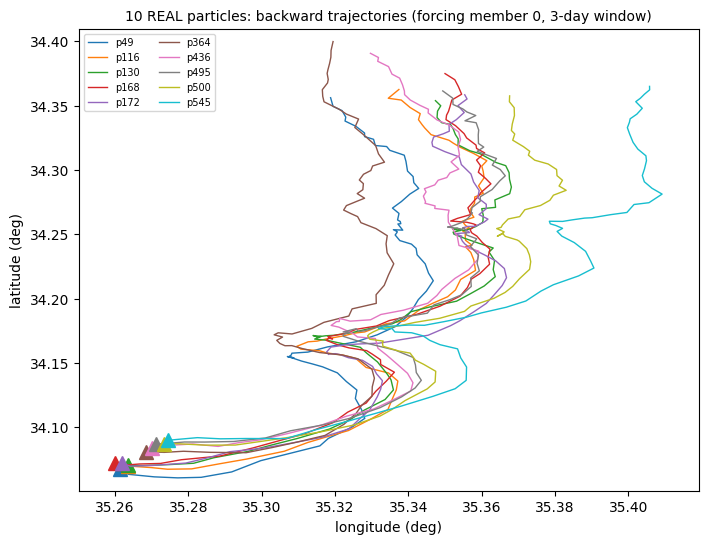

saved demo10_backward_trajectories.npz


In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
traj_all_lat = np.concatenate([traj[p]["lat"] for p in selected_10])
traj_all_lon = np.concatenate([traj[p]["lon"] for p in selected_10])
traj_pad = 0.01
add_land_background(ax)
for pid, c in zip(selected_10, colors):
    ax.plot(traj[pid]["lon"], traj[pid]["lat"], "-", color=c, linewidth=1, label=f"p{pid}")
    ax.plot(traj[pid]["lon"][0], traj[pid]["lat"][0], "^", color=c, markersize=10)
ax.set_xlim(traj_all_lon.min() - traj_pad, traj_all_lon.max() + traj_pad)
ax.set_ylim(traj_all_lat.min() - traj_pad, traj_all_lat.max() + traj_pad)
ax.set_title("10 REAL particles: backward trajectories (forcing member 0, 3-day window)", fontsize=10)
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.legend(fontsize=7, ncol=2)
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "02_backward_trajectories_10particles.png"), dpi=110), label="02_backward_trajectories_10particles.png")
plt.show()

save_with_retry(lambda: np.savez_compressed(
    os.path.join(RESULTS_DIR, "demo10_backward_trajectories.npz"),
    particle_ids=np.array(selected_10, dtype=object),
    **{f"lat_{pid}": traj[pid]["lat"] for pid in selected_10},
    **{f"lon_{pid}": traj[pid]["lon"] for pid in selected_10},
    **{f"t_{pid}": traj[pid]["t"] for pid in selected_10},
), label="demo10_backward_trajectories.npz")
print("saved demo10_backward_trajectories.npz")

### Backward-transport animation (10 real particles)

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
add_land_background(ax)
all_lat = np.concatenate([traj[p]["lat"] for p in selected_10])
all_lon = np.concatenate([traj[p]["lon"] for p in selected_10])
pad = 0.01
ax.set_xlim(all_lon.min() - pad, all_lon.max() + pad)
ax.set_ylim(all_lat.min() - pad, all_lat.max() + pad)
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
lines = [ax.plot([], [], "-", color=c, linewidth=1.2)[0] for c in colors]
points = [ax.plot([], [], "o", color=c, markersize=8)[0] for c in colors]
title = ax.set_title("")

def init():
    for l, p in zip(lines, points):
        l.set_data([], []); p.set_data([], [])
    return lines + points + [title]

def update(frame):
    for i, pid in enumerate(selected_10):
        lines[i].set_data(traj[pid]["lon"][:frame + 1], traj[pid]["lat"][:frame + 1])
        points[i].set_data([traj[pid]["lon"][frame]], [traj[pid]["lat"][frame]])
    t_now = traj[selected_10[0]]["t"][frame]
    title.set_text(f"Backward transport (real Stage III, member 0) -- t = {np.datetime64(t_now,'ns')}")
    return lines + points + [title]

n_frames = len(checkpoints)
anim = animation.FuncAnimation(fig, update, frames=n_frames, init_func=init, blit=False, interval=200)
mp4_path = os.path.join(RESULTS_DIR, "03_backward_animation.mp4")
gif_path = os.path.join(RESULTS_DIR, "03_backward_animation.gif")
save_animation_with_retry(anim, mp4_path, gif_path, fps=6)
plt.close(fig)

saved animation (MP4) to C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data\03_backward_animation.mp4


## 7. The same 10 real particles under multiple forcing members

The single-member view above (member 0) only shows one possible realization of
the coherent forcing perturbation. Below, the SAME 10 real particles' backward
trajectories are shown under **all 6 configured forcing members** (0-5, the
explicit development subset used throughout this run -- see Section 2) --
already computed by the single real Stage III run above (`records` already
contains every member; no additional backward transport is run here). Each panel
is one forcing member; the same particle keeps the same color across every panel,
so the spread introduced purely by the coherent per-member perturbation
(`delta_U_e`, T08) is directly visible.

  [retry 1/8] transient save error for 07_multimember_static.png: [Errno 22] Invalid argument: 'C:\\Users\\venka\\OneDrive\\Desktop\\SIH-2026\\project-v5\\results\\actual_data\\07_multimember_static.png'


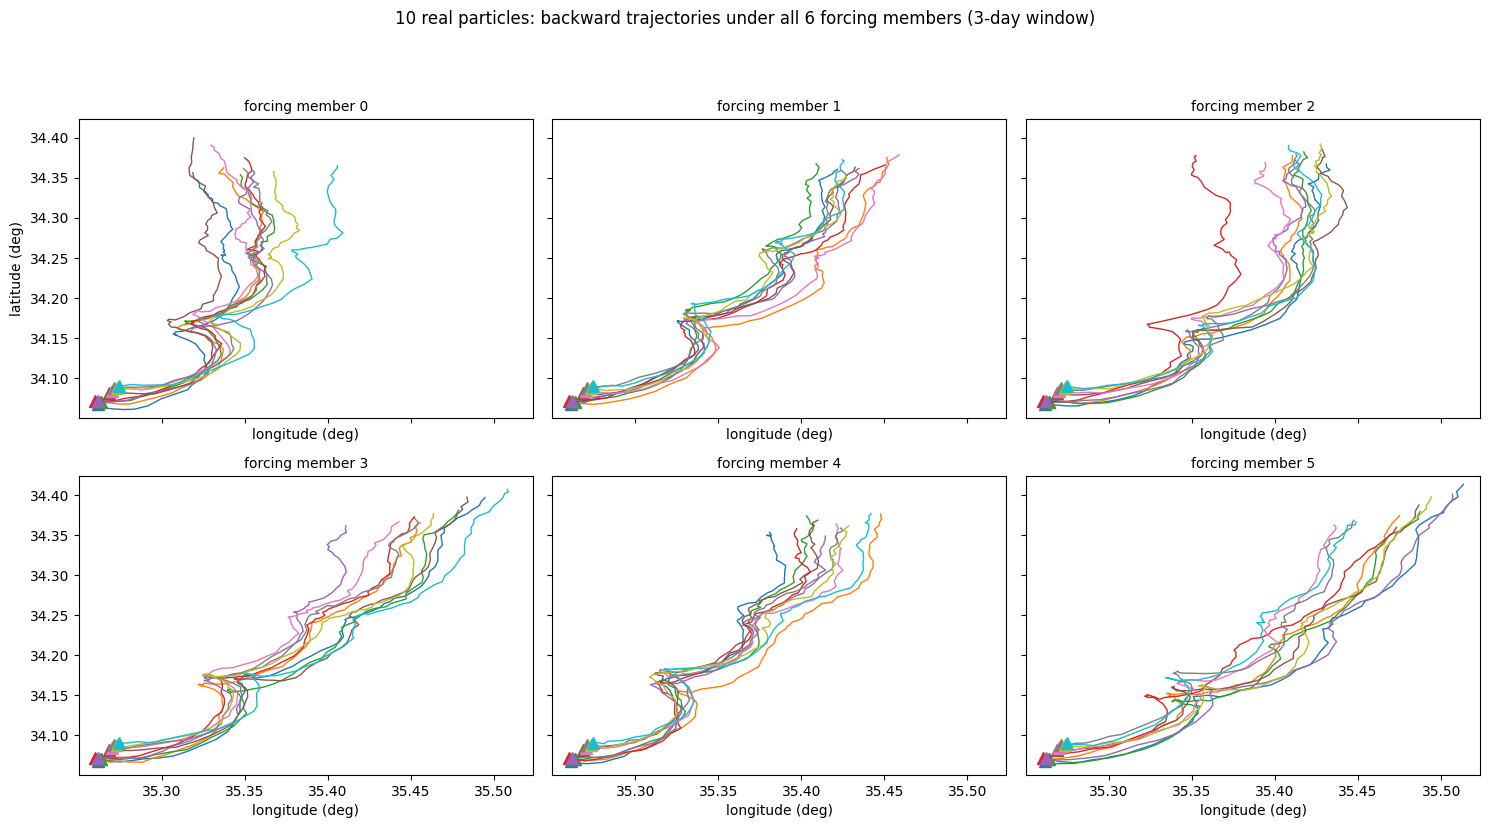

In [12]:
traj_multi = {pid: {} for pid in selected_10}
for pid in selected_10:
    for m in FORCING_MEMBER_IDS_USED:
        mask = (records.particle_id == pid) & (records.forcing_member_id == m)
        order = np.argsort(-records.timestamp[mask].astype("int64"))
        traj_multi[pid][m] = dict(lat=records.lat[mask][order], lon=records.lon[mask][order], t=records.timestamp[mask][order])

n_members = len(FORCING_MEMBER_IDS_USED)
ncols = 3
nrows = int(np.ceil(n_members / ncols))
all_lat_mm_static = np.concatenate([traj_multi[p][m]["lat"] for p in selected_10 for m in FORCING_MEMBER_IDS_USED])
all_lon_mm_static = np.concatenate([traj_multi[p][m]["lon"] for p in selected_10 for m in FORCING_MEMBER_IDS_USED])
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
for ax, m in zip(axes, FORCING_MEMBER_IDS_USED):
    add_land_background(ax)
    for pid, c in zip(selected_10, colors):
        tr = traj_multi[pid][m]
        ax.plot(tr["lon"], tr["lat"], "-", color=c, linewidth=1)
        ax.plot(tr["lon"][0], tr["lat"][0], "^", color=c, markersize=8)
    ax.set_title(f"forcing member {m}", fontsize=10)
    ax.set_xlabel("longitude (deg)")
for ax in axes[len(FORCING_MEMBER_IDS_USED):]:
    ax.axis("off")
axes[0].set_ylabel("latitude (deg)")
axes[0].set_xlim(all_lon_mm_static.min() - pad, all_lon_mm_static.max() + pad)
axes[0].set_ylim(all_lat_mm_static.min() - pad, all_lat_mm_static.max() + pad)
fig.suptitle(f"10 real particles: backward trajectories under all {n_members} forcing members (3-day window)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "07_multimember_static.png"), dpi=100), label="07_multimember_static.png")
plt.show()

### Multi-member backward-transport animation (10 real particles x 6 forcing members)

In [13]:
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()

all_lat_mm = np.concatenate([traj_multi[p][m]["lat"] for p in selected_10 for m in FORCING_MEMBER_IDS_USED])
all_lon_mm = np.concatenate([traj_multi[p][m]["lon"] for p in selected_10 for m in FORCING_MEMBER_IDS_USED])

lines_by_member = {}
points_by_member = {}
for ax, m in zip(axes, FORCING_MEMBER_IDS_USED):
    add_land_background(ax)
    ax.set_xlim(all_lon_mm.min() - pad, all_lon_mm.max() + pad)
    ax.set_ylim(all_lat_mm.min() - pad, all_lat_mm.max() + pad)
    ax.set_title(f"forcing member {m}", fontsize=10)
    ax.set_xlabel("longitude (deg)")
    lines_by_member[m] = [ax.plot([], [], "-", color=c, linewidth=1)[0] for c in colors]
    points_by_member[m] = [ax.plot([], [], "o", color=c, markersize=6)[0] for c in colors]
for ax in axes[len(FORCING_MEMBER_IDS_USED):]:
    ax.axis("off")
axes[0].set_ylabel("latitude (deg)")
suptitle_mm = fig.suptitle("", fontsize=13)

def init_mm():
    artists = []
    for m in FORCING_MEMBER_IDS_USED:
        for l, p in zip(lines_by_member[m], points_by_member[m]):
            l.set_data([], []); p.set_data([], [])
            artists += [l, p]
    return artists

def update_mm(frame):
    artists = []
    for m in FORCING_MEMBER_IDS_USED:
        for i, pid in enumerate(selected_10):
            tr = traj_multi[pid][m]
            lines_by_member[m][i].set_data(tr["lon"][:frame + 1], tr["lat"][:frame + 1])
            points_by_member[m][i].set_data([tr["lon"][frame]], [tr["lat"][frame]])
        artists += lines_by_member[m] + points_by_member[m]
    t_now = traj_multi[selected_10[0]][FORCING_MEMBER_IDS_USED[0]]["t"][frame]
    suptitle_mm.set_text(f"10 real particles backward under {n_members} forcing members -- t = {np.datetime64(t_now,'ns')}")
    return artists

anim_mm = animation.FuncAnimation(fig, update_mm, frames=n_frames, init_func=init_mm, blit=False, interval=200)
fig.tight_layout(rect=(0, 0, 1, 0.93))
mp4_path_mm = os.path.join(RESULTS_DIR, "08_multimember_animation.mp4")
gif_path_mm = os.path.join(RESULTS_DIR, "08_multimember_animation.gif")
save_animation_with_retry(anim_mm, mp4_path_mm, gif_path_mm, fps=6)
plt.close(fig)

saved animation (MP4) to C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data\08_multimember_animation.mp4


## 8. Monte Carlo particle density vs. T16 support/KDE heatmap

Two DIFFERENT things, shown side by side at two representative historical
timestamps (nearest to `t_obs`, and furthest back in the 3-day window):

- **top row -- RAW Monte Carlo density**: a plain 2D histogram of every VALID
  particle's position at that checkpoint, across ALL 6 forcing members combined
  (i.e. the full Monte Carlo ensemble's raw point cloud) -- pure descriptive
  binning (`matplotlib.pyplot.hist2d`), not a KDE, not a scientific algorithm.
- **bottom row -- T16 Support/KDE (existing Phase 2 screening signal)**: the SAME
  particles, through the project's own `iste.support_features.compute_support_map`
  (unmodified) -- a smoother, weighted/diversity-combined field, not a raw count.

Both rows use the SAME underlying real particle positions; only the
representation differs. Neither is a probability density.

In [14]:
historical_timestamps = checkpoints[checkpoints != RUN_T_OBS]
print(f"historical timestamp grid (reused from the real Stage III run): {len(historical_timestamps)} timestamps")

obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
print(f"support/candidate-search grid: {len(support_lat_grid)} x {len(support_lon_grid)} points "
      f"(data-driven: observation bbox UNION real backward-particle extent, padded {PAD_DEG} deg)")

NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()

historical timestamp grid (reused from the real Stage III run): 72 timestamps
support/candidate-search grid: 167 x 140 points (data-driven: observation bbox UNION real backward-particle extent, padded 0.03 deg)


  [retry 1/8] transient save error for 09_montecarlo_density.png: [Errno 22] Invalid argument: 'C:\\Users\\venka\\OneDrive\\Desktop\\SIH-2026\\project-v5\\results\\actual_data\\09_montecarlo_density.png'


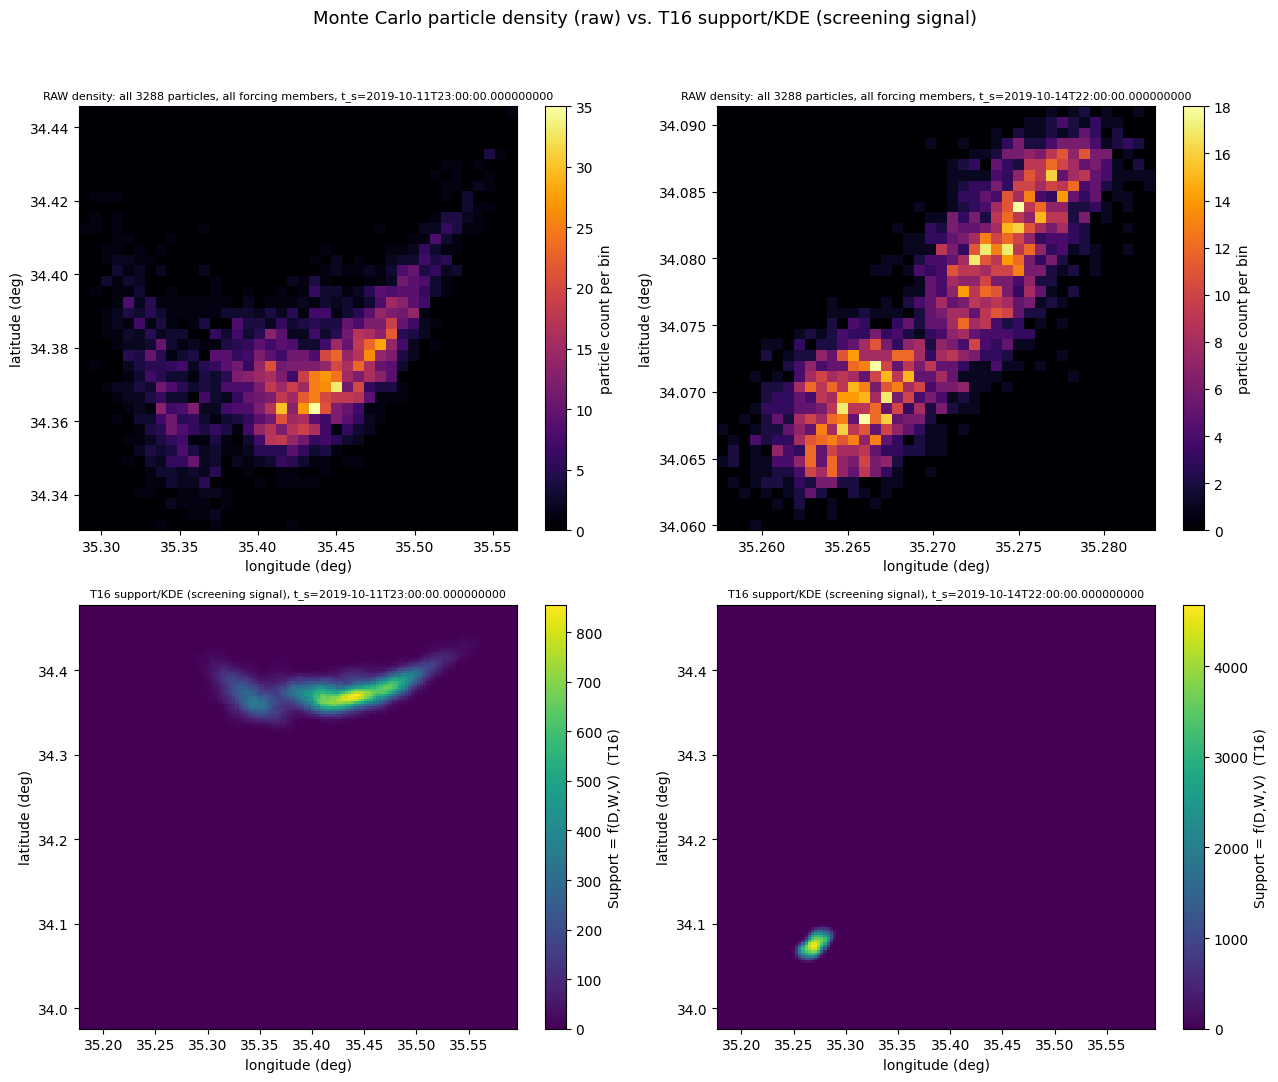

In [15]:
density_sample_t_s = [historical_timestamps[0], historical_timestamps[-1]]  # nearest, furthest

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for col, t_s in enumerate(density_sample_t_s):
    slice_ = query_particle_slice(records, t_s)
    vmask = slice_.valid
    lat_all, lon_all = slice_.lat[vmask], slice_.lon[vmask]
    n_points = len(lat_all)

    ax = axes[0, col]
    h = ax.hist2d(lon_all, lat_all, bins=40, cmap="inferno")
    fig.colorbar(h[3], ax=ax, label="particle count per bin")
    ax.set_title(f"RAW density: all {n_points} particles, all forcing members, t_s={np.datetime64(t_s,'ns')}", fontsize=8)
    ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")

    index = build_particle_neighborhood_index(slice_)
    lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)
    support_map = compute_support_map(index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
    support_grid = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    ax = axes[1, col]
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, support_grid, shading="auto", cmap="viridis")
    fig.colorbar(mesh, ax=ax, label="Support = f(D,W,V)  (T16)")
    ax.set_title(f"T16 support/KDE (screening signal), t_s={np.datetime64(t_s,'ns')}", fontsize=8)
    ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")

fig.suptitle("Monte Carlo particle density (raw) vs. T16 support/KDE (screening signal)", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "09_montecarlo_density.png"), dpi=100), label="09_montecarlo_density.png")
plt.show()

## 9. Historical timestamp processing: T14 -> T15 -> T16 -> T17 (full 3-day sweep)

Reuses the REAL Stage III checkpoint schedule the backward run above already
produced (all 72 non-`t_obs` checkpoints) as the configured historical timestamp
grid -- no new spacing/window is invented.

In [16]:
all_candidates = []
support_grids_by_t_s = {}
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)              # T14
    index = build_particle_neighborhood_index(slice_)          # T15
    support_map = compute_support_map(                          # T16
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    support_grids_by_t_s[float(t_s)] = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    candidates = find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config)  # T17
    all_candidates.extend(candidates)
t1 = time.time()
print(f"T14-T17 sweep over {len(historical_timestamps)} real historical timestamps took {t1 - t0:.1f}s")
print(f"TOTAL real hotspots/candidates found: {len(all_candidates)}")

hotspots_export = [
    {"candidate_id": c.candidate_id, "lat": c.y_peak, "lon": c.x_peak,
     "t_s": str(np.datetime_as_string(np.datetime64(c.t_s, "ns"), unit="s")),
     "support_score": c.support_score, "density_score": c.density_score,
     "weighted_support_score": c.weighted_support_score, "pixel_diversity_score": c.pixel_diversity_score}
    for c in all_candidates
]
write_json_with_retry(os.path.join(RESULTS_DIR, "hotspots.json"), hotspots_export, label="hotspots.json")
print(f"saved hotspots.json ({len(hotspots_export)} entries)")

T14-T17 sweep over 72 real historical timestamps took 63.7s
TOTAL real hotspots/candidates found: 280
saved hotspots.json (280 entries)


### Hotspot visualization

4 representative historical timestamps spanning the full 3-day backward window
(too many total hotspots over 72 timestamps to show all individually -- the top
10 by support are highlighted in red and carried forward to forward validation).

  [retry 1/8] transient save error for 04_hotspot_heatmap.png: [Errno 22] Invalid argument: 'C:\\Users\\venka\\OneDrive\\Desktop\\SIH-2026\\project-v5\\results\\actual_data\\04_hotspot_heatmap.png'


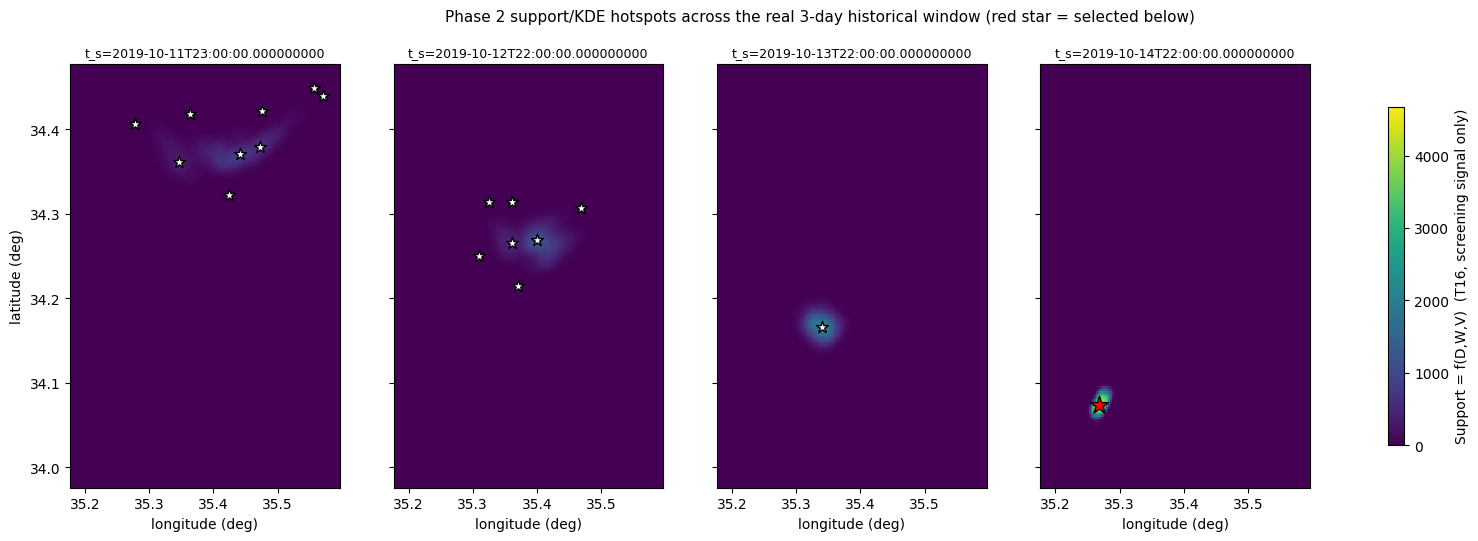

In [17]:
sample_idxs = np.linspace(0, len(historical_timestamps) - 1, 4).astype(int)
sample_t_s = [historical_timestamps[i] for i in sample_idxs]

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), sharex=True, sharey=True)
vmax = max(g.max() for g in support_grids_by_t_s.values())
top10_ids_preview = {c.candidate_id for c in sorted(all_candidates, key=lambda c: -c.support_score)[:10]}
for ax, t_s in zip(axes, sample_t_s):
    grid = support_grids_by_t_s[float(t_s)]
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, grid, shading="auto", cmap="viridis", vmin=0, vmax=vmax)
    cands_here = [c for c in all_candidates if np.datetime64(c.t_s, "ns") == np.datetime64(t_s, "ns")]
    for c in cands_here:
        is_top10 = c.candidate_id in top10_ids_preview
        ax.scatter([c.x_peak], [c.y_peak], marker="*", s=180 if is_top10 else 80,
                   c="red" if is_top10 else "white", edgecolors="black", linewidths=1, zorder=5)
    ax.set_title(f"t_s={np.datetime64(t_s,'ns')}", fontsize=9)
    ax.set_xlabel("longitude (deg)")
axes[0].set_ylabel("latitude (deg)")
fig.colorbar(mesh, ax=axes, label="Support = f(D,W,V)  (T16, screening signal only)", shrink=0.8)
fig.suptitle("Phase 2 support/KDE hotspots across the real 3-day historical window (red star = selected below)", fontsize=11)
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "04_hotspot_heatmap.png"), dpi=100), label="04_hotspot_heatmap.png")
plt.show()

## 10. Select 10 hotspots for forward validation

**Selection rule (explicit, not a new ranking algorithm):** the top 10 candidates
by `support_score` across ALL real historical timestamps in the 3-day window --
`support_score` is an existing T17 output field (candidates are already returned
sorted by it); this step only takes the top 10 of an already-computed,
already-sorted list. T25's forward-accuracy-based ranking is applied LATER, to
these same 10 candidates once forward-validated.

In [18]:
top10_candidates = sorted(all_candidates, key=lambda c: -c.support_score)[:10]
top10_t_s = sorted({np.datetime64(c.t_s, "ns") for c in top10_candidates})
print(f"selected {len(top10_candidates)} of {len(all_candidates)} available candidates for forward validation")
print(f"spanning {len(top10_t_s)} distinct historical timestamps")

print(chr(10) + f"{'candidate_id':30s} {'lat':>9s} {'lon':>9s} {'support_score':>14s}")
for c in top10_candidates:
    print(f"{c.candidate_id:30s} {c.y_peak:9.4f} {c.x_peak:9.4f} {c.support_score:14.2f}")

selected 10 of 280 available candidates for forward validation
spanning 10 distinct historical timestamps

candidate_id                         lat       lon  support_score
2019-10-14T22:00:00_cand000      34.0735   35.2681        4675.43
2019-10-14T21:00:00_cand000      34.0735   35.2741        4573.32
2019-10-14T20:00:00_cand000      34.0735   35.2831        4411.98
2019-10-14T19:00:00_cand000      34.0765   35.2891        4288.16
2019-10-14T18:00:00_cand000      34.0795   35.2981        4153.03
2019-10-14T17:00:00_cand000      34.0855   35.3071        3961.17
2019-10-14T16:00:00_cand000      34.0885   35.3131        3807.23
2019-10-14T15:00:00_cand000      34.0975   35.3221        3656.80
2019-10-14T14:00:00_cand000      34.1035   35.3311        3529.66
2019-10-14T13:00:00_cand000      34.1125   35.3341        3463.28


## 11. Forward propagation + predicted-vs-observed comparison (T18-T25)

Uses the integrated T26 pipeline (`iste.phase2_pipeline.run_phase2_pipeline`) --
the SAME orchestrator validated on synthetic data in
`notebooks/T26_phase2_pipeline_check.ipynb` -- restricted to just the historical
timestamps that produced the 10 selected hotspots. Internally this calls, per
candidate: T18 (`compute_forward_particle_budget`, `N_forward = min(X,Y)`), T19
(weighted core sampling), T20/T21 (forward propagation under the SAME 6-member
forcing subset, coherent per member, propagated exactly to `RUN_T_OBS`), T22
(predicted vs. observed slick footprints), T23 (forward accuracy), T24
(candidate-level aggregation), and finally T25 (filtering/ranking) once over all
10.

In [19]:
FOOTPRINT_BANDWIDTH_M = 400.0
phase2_config = Phase2RunConfig(
    historical_timestamps=tuple(top10_t_s), t_obs=RUN_T_OBS,
    support_query_lat_grid=support_lat_grid, support_query_lon_grid=support_lon_grid,
    neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, support_config=support_config,
    extraction_config=extraction_config, forward_budget_config=ForwardBudgetConfig(X=20),
    forcing_member_ids=FORCING_MEMBER_IDS_USED, forward_dt_seconds=DT_SECONDS,
    footprint_lat_grid=support_lat_grid, footprint_lon_grid=support_lon_grid,
    footprint_bandwidth_m=FOOTPRINT_BANDWIDTH_M,
    comparison_config=ComparisonConfig(metric="combined_overlap_fp"),
    screening_config=ScreeningConfig(mode="top_k", top_k=10, merge_separation_m=1500.0),
    master_seed=123,
)

t0 = time.time()
result = run_phase2_pipeline(records, ocean, ensemble, ocean.lat, ocean.lon, K, adapted, phase2_config)
t1 = time.time()
print(f"T18-T25 (integrated pipeline) took {t1 - t0:.1f}s")

found_ids = {c.candidate.candidate_id for ts in result.timestamps for c in ts.candidates}
top10_ids = {c.candidate_id for c in top10_candidates}
print(f"pipeline processed {len(found_ids)} candidates; matches the Section 10 selection exactly: {found_ids == top10_ids}")
assert found_ids == top10_ids

print(chr(10) + f"n forward-validated candidates: {len(result.decisions)}")
for dcn in sorted(result.decisions, key=lambda x: (x.rank is None, x.rank if x.rank else 0)):
    print(f"  {dcn.record.candidate_id}  accepted={dcn.accepted}  rank={dcn.rank}  "
          f"error={dcn.record.candidate_forward_error}  reason={dcn.rejection_reason}")

T18-T25 (integrated pipeline) took 13.2s
pipeline processed 10 candidates; matches the Section 10 selection exactly: True

n forward-validated candidates: 10
  2019-10-14T22:00:00_cand000  accepted=True  rank=1  error=0.22545874517224182  reason=
  2019-10-14T21:00:00_cand000  accepted=True  rank=2  error=0.26111594397332377  reason=
  2019-10-14T20:00:00_cand000  accepted=True  rank=3  error=0.38435372892236747  reason=
  2019-10-14T19:00:00_cand000  accepted=True  rank=4  error=0.40675397718909734  reason=
  2019-10-14T18:00:00_cand000  accepted=True  rank=5  error=0.4542808706459697  reason=
  2019-10-14T17:00:00_cand000  accepted=True  rank=6  error=0.49604921701309257  reason=
  2019-10-14T13:00:00_cand000  accepted=True  rank=7  error=0.572845137178324  reason=
  2019-10-14T15:00:00_cand000  accepted=True  rank=8  error=0.5978950920419058  reason=
  2019-10-14T14:00:00_cand000  accepted=True  rank=9  error=0.6347892187018158  reason=
  2019-10-14T16:00:00_cand000  accepted=True  

### Predicted vs. observed: best- and worst-ranked of the 10 forward-validated candidates

  [retry 1/8] transient save error for 05_predicted_vs_observed.png: [Errno 22] Invalid argument: 'C:\\Users\\venka\\OneDrive\\Desktop\\SIH-2026\\project-v5\\results\\actual_data\\05_predicted_vs_observed.png'


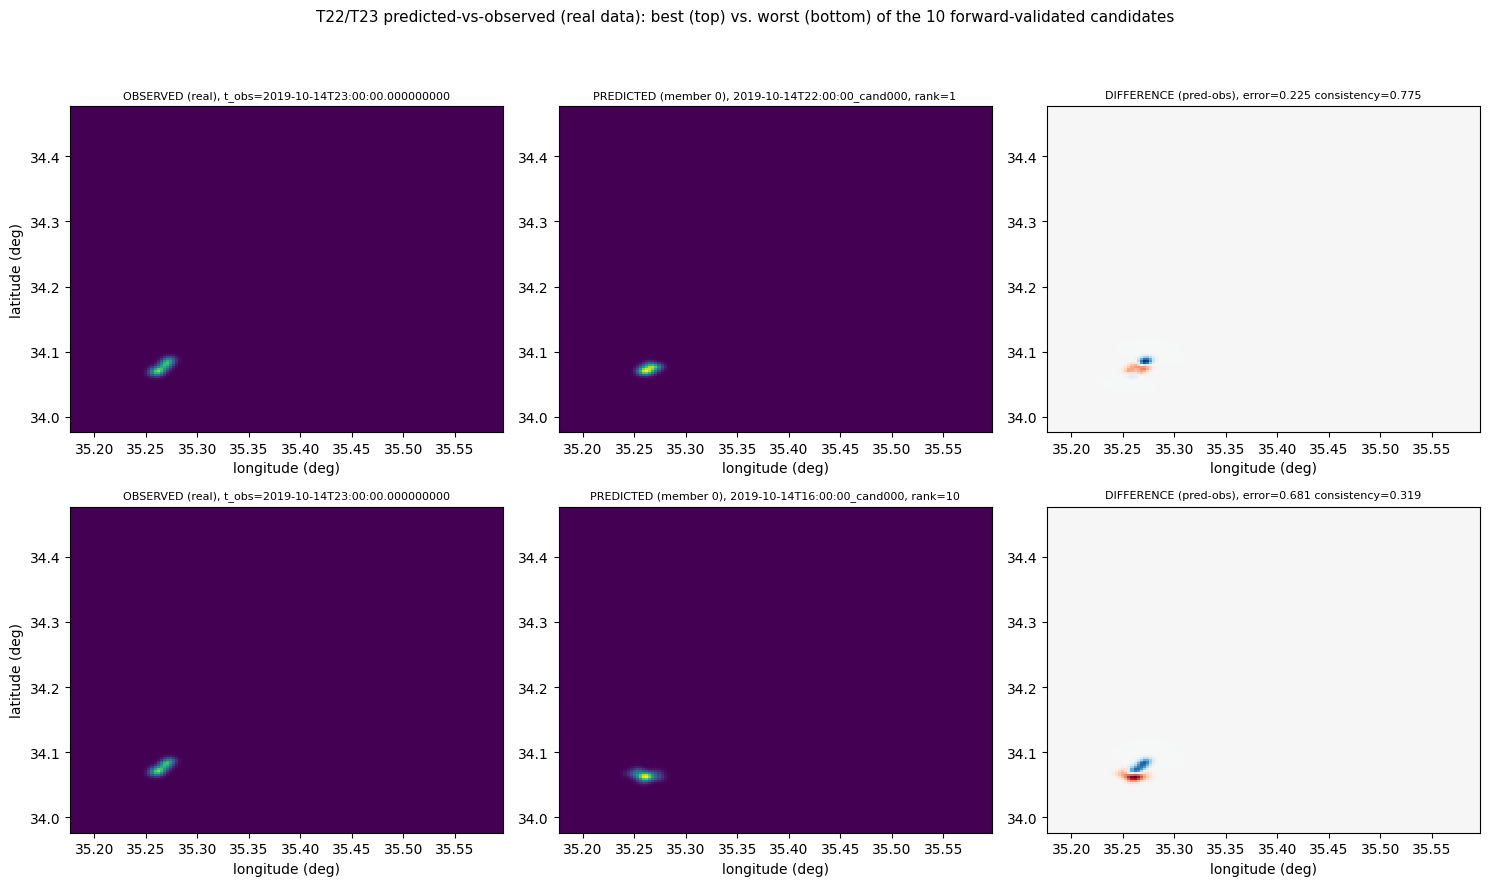

best: 2019-10-14T22:00:00_cand000 rank=1 error=0.2255
worst: 2019-10-14T16:00:00_cand000 rank=10 error=0.6807


In [20]:
def find_pipeline_candidate(cand_id):
    for ts in result.timestamps:
        for c in ts.candidates:
            if c.candidate.candidate_id == cand_id:
                return c
    return None

by_rank = sorted([d for d in result.decisions if d.accepted], key=lambda d: d.rank)
best, worst = by_rank[0], by_rank[-1]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
vmax2 = max(np.nanmax(result.observed_footprint.density),
            *[np.nanmax(find_pipeline_candidate(d.record.candidate_id).predicted_footprints[0].density) for d in [best, worst]])
for row, dcn in enumerate([best, worst]):
    c = find_pipeline_candidate(dcn.record.candidate_id)
    axes[row, 0].pcolormesh(support_lon_grid, support_lat_grid, result.observed_footprint.density, shading="auto", cmap="viridis", vmin=0, vmax=vmax2)
    axes[row, 0].set_title(f"OBSERVED (real), t_obs={RUN_T_OBS}", fontsize=8)
    axes[row, 1].pcolormesh(support_lon_grid, support_lat_grid, c.predicted_footprints[0].density, shading="auto", cmap="viridis", vmin=0, vmax=vmax2)
    axes[row, 1].set_title(f"PREDICTED (member 0), {dcn.record.candidate_id}, rank={dcn.rank}", fontsize=8)
    diff = c.predicted_footprints[0].density - result.observed_footprint.density
    lim = np.nanmax(np.abs(diff))
    axes[row, 2].pcolormesh(support_lon_grid, support_lat_grid, diff, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[row, 2].set_title(f"DIFFERENCE (pred-obs), error={dcn.record.candidate_forward_error:.3f} consistency={dcn.record.candidate_forward_consistency:.3f}", fontsize=8)
    for ax in axes[row]:
        ax.set_xlabel("longitude (deg)")
    axes[row, 0].set_ylabel("latitude (deg)")
fig.suptitle("T22/T23 predicted-vs-observed (real data): best (top) vs. worst (bottom) of the 10 forward-validated candidates", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "05_predicted_vs_observed.png"), dpi=100), label="05_predicted_vs_observed.png")
plt.show()
print(f"best: {best.record.candidate_id} rank={best.rank} error={best.record.candidate_forward_error:.4f}")
print(f"worst: {worst.record.candidate_id} rank={worst.rank} error={worst.record.candidate_forward_error:.4f}")

## 12. Final top-10 candidate details (T24/T25)

The ranking below comes entirely from T25's existing forward-accuracy filtering/
ranking (`filter_and_rank_candidates`) -- no new "overall hotspot score" is
computed, and backward support is never combined with forward error. Each row is
one candidate's SOURCE (its historical peak position/time) with its forward error
against the real observed slick.

  [retry 1/8] transient save error for 06_final_top10_table.png: [Errno 22] Invalid argument: 'C:\\Users\\venka\\OneDrive\\Desktop\\SIH-2026\\project-v5\\results\\actual_data\\06_final_top10_table.png'


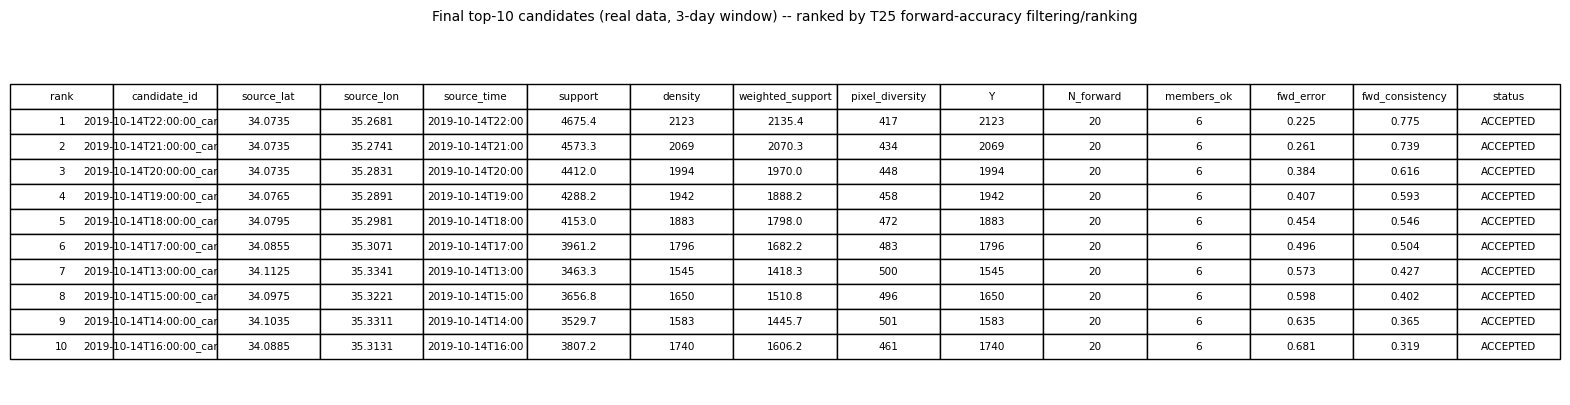

In [21]:
ranked_decisions = sorted(result.decisions, key=lambda d: (d.rank is None, d.rank if d.rank is not None else 0))
col_labels = ["rank", "candidate_id", "source_lat", "source_lon", "source_time", "support", "density",
              "weighted_support", "pixel_diversity", "Y", "N_forward", "members_ok", "fwd_error", "fwd_consistency", "status"]
rows = []
for dcn in ranked_decisions:
    r = dcn.record
    rows.append([
        dcn.rank if dcn.rank else "-", r.candidate_id, f"{r.y_peak:.4f}", f"{r.x_peak:.4f}",
        str(r.t_s)[:16], f"{r.support_score:.1f}", f"{r.density_score:.0f}",
        f"{r.weighted_support_score:.1f}", f"{r.pixel_diversity_score:.0f}",
        r.core_particle_count_Y, r.forward_particle_count_N_forward, len(r.forcing_members_validated),
        f"{r.candidate_forward_error:.3f}" if r.forward_validation_status == "validated" else "n/a",
        f"{r.candidate_forward_consistency:.3f}" if r.forward_validation_status == "validated" else "n/a",
        "ACCEPTED" if dcn.accepted else f"rejected: {dcn.rejection_reason[:30]}",
    ])

fig, ax = plt.subplots(figsize=(20, 0.5 + 0.4 * len(rows)))
ax.axis("off")
table = ax.table(cellText=rows, colLabels=col_labels, loc="center", cellLoc="center")
table.auto_set_font_size(False); table.set_fontsize(7.5); table.scale(1, 1.5)
ax.set_title(f"Final top-{len(rows)} candidates (real data, 3-day window) -- ranked by T25 forward-accuracy filtering/ranking", fontsize=10, pad=20)
save_with_retry(lambda: fig.savefig(os.path.join(RESULTS_DIR, "06_final_top10_table.png"), dpi=110, bbox_inches="tight"), label="06_final_top10_table.png")
plt.show()

### Save the final machine-readable candidate artifact

Reuses T26's own serialization convention (`save_phase2_artifact`) -- no second,
independent artifact format is invented.

In [22]:
artifact_path = os.path.join(RESULTS_DIR, "final_top10_candidates.json")
save_with_retry(lambda: save_phase2_artifact(result.decisions, phase2_config, artifact_path), label="final_top10_candidates.json")
with open(artifact_path, "r", encoding="utf-8") as f:
    reloaded_artifact = json.load(f)
print(f"saved + verified final machine-readable artifact: {artifact_path} ({len(reloaded_artifact['candidates'])} candidates)")

saved + verified final machine-readable artifact: C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data\final_top10_candidates.json (10 candidates)


## 13. Outputs saved

In [23]:
output_files = sorted(os.listdir(RESULTS_DIR))
print(f"{len(output_files)} files saved under {RESULTS_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(RESULTS_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

15 files saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data:
  01_observation.png  (109.8 KB)
  02_backward_trajectories_10particles.png  (108.5 KB)
  03_backward_animation.mp4  (105.1 KB)
  04_hotspot_heatmap.png  (53.4 KB)
  05_predicted_vs_observed.png  (58.2 KB)
  06_final_top10_table.png  (76.3 KB)
  07_multimember_static.png  (249.7 KB)
  08_multimember_animation.mp4  (327.6 KB)
  09_montecarlo_density.png  (94.1 KB)
  demo10_backward_trajectories.npz  (20.7 KB)
  final_top10_candidates.json  (31.8 KB)
  hotspots.json  (86.2 KB)
  observation_summary.json  (0.4 KB)
  stage3_history_summary.txt  (3.8 KB)
  stage3_particle_history.npz  (4853.6 KB)


## 14. Execution / validation checklist

In [24]:
checks = {
    "548 real input particles adapted": adapted.n_particles == 548,
    "historical trajectories exist (Stage III records)": records.n_records > 0,
    "10 demonstration particles present": len(selected_10) == 10,
    "complete historical positions saved (NPZ)": os.path.exists(os.path.join(RESULTS_DIR, "stage3_particle_history.npz")),
    "hotspots/candidates generated": len(all_candidates) > 0,
    "up to 10 forward-validated candidates processed": 0 < len(result.decisions) <= 10,
    "predicted-vs-observed comparisons generated": os.path.exists(os.path.join(RESULTS_DIR, "05_predicted_vs_observed.png")),
    "final top-10 output generated": os.path.exists(os.path.join(RESULTS_DIR, "final_top10_candidates.json")),
    "montecarlo density heatmap generated": os.path.exists(os.path.join(RESULTS_DIR, "09_montecarlo_density.png")),
}
for name, ok in checks.items():
    print(f"[{'OK' if ok else 'FAIL'}] {name}")
assert all(checks.values()), "one or more end-to-end validation checks failed"
print(chr(10) + "All end-to-end validation checks passed.")

[OK] 548 real input particles adapted
[OK] historical trajectories exist (Stage III records)
[OK] 10 demonstration particles present
[OK] complete historical positions saved (NPZ)
[OK] hotspots/candidates generated
[OK] up to 10 forward-validated candidates processed
[OK] predicted-vs-observed comparisons generated
[OK] final top-10 output generated
[OK] montecarlo density heatmap generated

All end-to-end validation checks passed.


## Interpretation limits (real-data safety, restated)

- The environmental forcing data used (`data/ocean.nc`/`data/wind.nc`, Oct 2019) is
  a **known mismatch** with the true observation date (June 2019) -- this run
  demonstrates Phase 2 pipeline MECHANICS on real inputs, not a physically accurate
  reconstruction of the true event. See Section 2.
- The 3-day/1-hour backward window is an **explicit user-scoped reduction** from
  the full 14-day dataset, recorded for auditability (Section 0/4), not a silent
  substitution.
- Backward-tracked particle positions are historical transport STATES -- never
  described as observations.
- `support_score`/hotspots, and the raw Monte Carlo density heatmap, are a
  candidate-discovery SCREENING/descriptive signal -- never a posterior
  probability; a hotspot is never a confirmed source.
- `candidate_forward_error`/`candidate_forward_consistency` are a physical-
  consistency SCREENING quantity -- never a formal likelihood or posterior.
- The final table/artifact is a **forward-screened candidate set**, not a
  confirmed source and not a final formal source-inference result (that is a
  later, not-yet-implemented stage).
- Forcing ensemble actually used: 6 of the configured 50 members (`(0,1,2,3,4,5)`),
  an explicit, recorded development subset (Section 2) -- never a silent
  substitution.